This porject is aiming to be a simple tool to preprocess the image data of organoids.

The steps include resizing, normalization, noise reducation, and data augmentation. 

The tool will be implemented in Python and will utilize libraries such as OpenCV, NumPy, and TensorFlow for efficient processing. 

The goal is to create a streamlined workflow that can be easily integrated into existing pipelines for organoid research.

In [1]:
#Import necessary libraries
import config
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage.exposure import is_low_contrast
from skimage import restoration, img_as_float, img_as_float64
from skimage.restoration import rolling_ball
from PIL import Image
import albumentations as A
import os, glob
import pathlib
from scipy import ndimage
from scipy.stats import entropy
from scipy.signal import convolve2d
from scipy.ndimage import median_filter
import pandas as pd
from  tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import ipywidgets as widgets



In [2]:

def image_import(directory_path, batch_size=None, extensions=('*.tif', '*.tiff', '*.TIF', '*.TIFF')):
    """
    retrieve all image file paths from the specified directory
    
    Parameters:
                directory_path = "path/to/your/image/directory", string
                batch_sieze: int or None, if None, read all images otherwise read batch_size number of images
                extensions: picture format supported.  Default types are :tiff and tif
    
    Return:
                image_path, a list of strings contains all images addresses in order as in the directory.
    """
    if not pathlib.Path(directory_path).is_dir():
        raise ValueError(f"Directory does not exist: {directory_path}") # Check if the directory exists before attempting to read images
    
    image_paths = []
    for ext in extensions:
        image_paths.extend(glob.glob(str(pathlib.Path(directory_path) / ext), recursive=True))

    image_paths = list(set(image_paths))  # Remove duplicates
    if batch_size is not None and batch_size > 0:
        image_paths = image_paths[:batch_size]

    print(f"found {len(image_paths)} images.")
    return image_paths


After load the images, the next step is to test if all images are ready to be process. The cells below will check the
format and integrity of loaded. 

In [3]:
 
def verify_images(image_paths):
    """
    verify integerty of all images in the directory
    
    Parameter:
                image_paths: A list of strings.
                
    Return:     A list of strings contains the damaged image address, None if all passed the test.
                print out errors found
    """
    corrupted_images = []
    for idx, path in enumerate(image_paths):
        try: 
            with Image.open(path) as verIm:
                verIm.verify()  # Open the image and verify its integrity 
            with Image.open(path) as verIm:
                verIm.load()  # Load the image to ensure it's fully readable
        except Exception as e:
            print(f"Corrupted image at index {idx}: {path}")
            print(f"Error details: {str(e)}")
            corrupted_images.append(path)
    return corrupted_images

In [4]:

def load_images(image_paths, target_size=(512, 512)):
    """
    Open images from image_image path.
    
    Parameters:
                image_paths: a list of string, image addresses
                target_size: a tuple has two intgers, decide the size of image or the number of pixels in the array
    
    Return:     
                image_dict: a dictionary contains keys(the address strings) and items(2D arrays)
    """
    image_dict = {}
    for path in image_paths:
        i = cv2.imread(path)
        if i is None:
            print(f"Failed to load image: {path}")
            continue
        
        resized_img = cv2.resize(i, target_size, interpolation=cv2.INTER_AREA) # Resize the image to the size desired
        image_dict[path] = resized_img
    print(f"Successfully loaded {len(image_dict)} images.")
    return image_dict


Build a smart pipeline to determine which pre-processing should be applied to an image. 
First, determine if the image comes is a brightfield or fluorescent based on 3 features. 
A fluorescent image has the dark background, its corners of edges usually remain low inensity(or close to 0 out of 255). Likewise, the image usually has more than 50% dark are, and the ratio can be found out by intensity histogram. I use low 25% percentile as default. Finally, The image should have stronger brightness contrast than the brightfield. Apply these three features, the code should easily flag the image type.   

In [ ]:
# Determine the image type
def image_type_determination(image):
    """
    Based on the features, automatically determine if the image was fluorescence or brightfield.
    
    paremeter: 
                image: BGR , data type: unit8 (0-255)
    Expected return:
                str: 'flu' or 'bri'
    """
    # Transform the loaded image to grayscale for later feature calculation
    gray= cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) /255.0

    # Feature 1: background light distribution, calculated by picking the average intensity of four corner edges
    h, w  = gray.shape
    corner_size = max(1,min(50,h//10, w//10))
    top_l = gray[0:corner_size, 0:corner_size]
    top_r = gray[0:corner_size, w-corner_size:w]
    bottom_l = gray[h-corner_size:h, 0:corner_size]
    bottom_r = gray[h-corner_size:h, w-corner_size:w]
    center = gray[h//2-corner_size//2:h//2+corner_size//2, 
                  w//2-corner_size//2:w//2+corner_size//2]
    corner_mean = (np.mean(top_l)+np.mean(top_r)+np.mean(bottom_l)+np.mean(bottom_r)) /4.0

    # Feature 2: global standard deviation
    g_std= np.std(gray)

    # Feature 3: Histogram Equalization, pick ratio the of 25% low inensity 
    hist,_ = np.histogram(gray, bins=20)
    low_intensity_ratio = np.sum(hist[:5])/ np.sum(hist)

    # If the image is fluorescent, the corner brightness should be small, high global std, and high ratio of low inensity through out the whole
    # I weight each features almost evenly, but the corner measurement is more reliable, and so it influnces more on the final score.
    
    is_flu_score = (corner_mean < 0.25) * 0.4 + (g_std > 0.25) *0.3 + (low_intensity_ratio> 0.5) *0.3
    is_flu = is_flu_score > 0.5

    return 'flu' if  is_flu else 'bri', gray,[np.mean(top_l), np.mean(top_r), np.mean(bottom_l), np.mean(bottom_r),np.mean(center)]

Since each image was taken in various condition, it is not wise to apply all of processing steps to every loaded. 
Instead, the image will be taken into evaluation, and be flagged when it meets the criteria. The parameters that use to determine the condition are referenced from articles. The citations are written later. 

In [23]:

def image_preprocess_flag(image):
    """
    Analyze the image, flag the preprocessing label 

    Parameters:
                BGR image, data type: unit8(0-255)
    return: 
             dict: {
                'need_illumination_correction': bool,
                'need_deconvolution': bool,
                'need_clahe': bool,
                'need_denoise': bool,
                'metrics': {...}
                }
"""
    itype, gray, means = image_type_determination(image)

    means = np.array(means)
    Max_means = max(means)
    Min_means = min(means)

    gray_uint8 = (gray * 255.0).astype(np.uint8) #convert the normalized image back to uint8 format for deconvlution


    #======Illumination correction sect======
    #Calculate the uniformity ratio, add a negalectable number to denominator to avoid division by zero errors
    illumination_uniformity = Min_means / (Max_means + 1e-10)
    # Coefficient variation, again add a small number to avoid errors
    cv_score = np.std(means) / np.mean(means + 1e-10)

    # QF
    qf = illumination_uniformity * (1-cv_score) * 100
    # attach a bool value for illumination correction test
    IC_need = (qf < 83) or (cv_score > 0.15)  


    #======Background Correction sect=======
    centermean = means[4] #retrieve the center mean of the image
    corner_std = np.std(means[:4]) #standard deviation from the corner means

    #The image needs background correction if uneven brightness disturibution between the center and corners,
    #or if big std in corners. 
    # different type of image should apply different standard. The fluorescent image should only need bc if be found obivous uneven distribution
    if itype == 'flu':
        need_bc = (centermean > 1.5 * np.mean(means[:4])) or (corner_std > 0.08) #If center is 50% brighter than corners, or std in corners is greater than 8%
    else:
        need_bc = (centermean > 1.3 * np.mean(means[:4])) or (corner_std > 0.05) #If center is 30% brighter than corners, or std in corners is greater than 5%


    #======Deconvolution sect======
    #Laplacian variation for blur detection, value <100 likely needs to deconv  
    laplacian_var = cv2.Laplacian(gray_uint8, cv2.CV_64F).var() #High var means image is sharp, otherwise is likely blurry and need to go through deconvolution

    #Tengengrad, another indicator use for blur detection,  value <500 is likely needs to deconv 
    #Compute Sobel gradients in X and Y
    gx = cv2.Sobel(gray_uint8, cv2.CV_64F, 1, 0, ksize = 3)
    gy = cv2.Sobel(gray_uint8, cv2.CV_64F, 0, 1, ksize = 3)
    #Mean of squared gradient magnitude
    tengengrad = np.mean(gx**2 +gy**2)

    # Evaluate peak signal to noise signal. 
    smoothed = cv2.GaussianBlur(gray, (3,3),0)
    noise = np.std(gray.astype(np.float32) - smoothed.astype(np.float32))
    estimated_snr = 20 * np.log10(np.std(gray.astype(np.float32)) / (noise +1e-10)) #compute the value to decibels

    #Apply three evaluations to determine whether goes to deconv process
    need_deconv = (laplacian_var < 100 or tengengrad < 500) and estimated_snr > 25

    #===== Denoise evaluation sect ====
    if itype == 'flu':
        denoise_threshold = 0.03
        clahe_clip = 2.0
    else:
        denoise_threshold =  0.05
        clahe_clip = 0.8
        
    need_denoise = noise > denoise_threshold or estimated_snr < 20


    #====== Contrast sect ======
    #Calculate the image entropy with histogram equalization
    hist,_ = np.histogram(gray, bins= 256, range=(0,1))
    hist = hist / (hist.sum() + 1e-10) #Normalization 

    entro = entropy(hist, base = 2) # compute shannon entropy 

    #Apply is low constrast function from Skimage
    is_contrast = is_low_contrast(gray, fraction_threshold = 0.3)

    # Determine if the image should be applied CLAHE
    if itype == 'bri':
        need_clahe = False  
    else:
        need_clahe = is_contrast or (entro < 5.0)
    


    return {
        'image_type': itype,
        'need_illumination_correction': IC_need, 'need_deconvolution': need_deconv,
        'need_clahe': need_clahe, 'need_denoise': need_denoise, 
        'need_background_correction': need_bc,
        'metrics':{
            'qf': round(qf, 2), 'cv_score': round(cv_score, 4),
            'illumination_uniformity': round(illumination_uniformity, 4),
            'lapacian': round(laplacian_var, 2), 'tenengrad': round(tengengrad, 2),
            'entropy': round(entro, 3), 'estimated_snr': round(estimated_snr, 2),
            'noise_estimate': round(noise, 4), 'CLAHE_clip': clahe_clip
        } 
    }


In [7]:
#Background Correction
def bc_polyfit(image, tags, downsample_factor = 0.25):
    """
    While it is always better to do background correct the images with Acquisition method, this modual
    uses 2D polynomial fitting to achieve a posteriori correction(it is approximating a surface that best fits the given data points).
    Note: it will introduces some image artiifacts so that should apply Gaussian blurring after as a compensation for the illumination.
    
    Parameters: 
                image: input image, np array, gray scale or multichannel
                tags: dictionary retrieve from flagging function
                downsample_factor: float, control shrinking factor when calculating background polynomial fitting coefficient
    
    """

    # check the dimension of the input, recursive call to process each channel separately
    if image.ndim == 3:
        channels = []
        for c in range(image.shape[2]):
            ch = image[:, :, c] 
            ch_corrected = bc_polyfit(ch, tags, downsample_factor)
            channels.append(ch_corrected)
        return np.stack(channels, axis=2).astype(np.float32)
    
    gray = image
    h, w = gray.shape
    #Downsaple the image to speed up the fitting process, but keep the original for later correction
    small_h, small_w = int(h * downsample_factor), int(w * downsample_factor)
    gray_small = cv2.resize(gray, (small_w, small_h), interpolation=cv2.INTER_AREA)

    # generate the coordinate of a grid 
    x = np.linspace(0,1,small_w)
    y = np.linspace(0,1,small_h)
    xv, yv = np.meshgrid(x,y)

    #Smaller degree, smaller the fitting error and grid, but the fitting will be more sensitive to noise and outliers.
    #degree = 2, so that x^2, xy, y^2 are included in the polynomial fitting.
    A = np.c_[np.ones(small_h * small_w), xv.ravel(), yv.ravel(), 
              xv.ravel() **2, xv.ravel() * yv.ravel(), yv.ravel() **2] #concatenate the polynomial terms along the columns
    coeffs, _, _, _ = np.linalg.lstsq(A, gray_small.ravel(), rcond=None)  # Solve for the coefficients of the polynomial

    #reconstruct the backround surface using the fitted polynomial coefficients, orginal size
    x_full = np.linspace(0, 1, w)
    y_full = np.linspace(0, 1, h)
    xv_full, yv_full = np.meshgrid(x_full, y_full)
    A_full =np.c_[np.ones(h * w), xv_full.ravel(), yv_full.ravel(),
                  xv_full.ravel() **2, xv_full.ravel() * yv_full.ravel(), yv_full.ravel() **2]
    background = np.dot(A_full, coeffs).reshape(h, w)

    # Correction
    bg_mean = np.mean(background)
    corrected =(gray.astype(np.float32) / (background + 1e-10)) * bg_mean #orignal image / background * mean of background
    corrected = np.clip(corrected, 0, 1) # value is either 0, 1, or between 0 and 1


    return corrected.astype(np.float32)  # Return a single-channel image


def bc_rollingball(image, radius = 50):
    """"
    Alternative algorthim for doing posteriori correction. Advance in edge friendly, lesser artifact introduce compares to polyfit.
    The skimage implementation would assume the background has low intensity(dark). So if processing a brightfield, using polyfit would be
    recommanded, otherwise, first you have to invert the image.

    Paremeters:
                image, input image, np array[0,1], grayscale or multichannel, rolling ball can handle datatype other than np.uint8
                radius: int, ball-shape kernel that controls smoothing            
    """

    #channel check
    # recursive call the function for each channel
    if image.ndim == 3:
        channels = []
        for i in range(image.shape[2]):
            ch = image[:,:, i]
            ch_correct =bc_rollingball(ch, radius)
            channels.append(ch_correct)
        return np.stack(channels, axis = -1).astype(np.float32)

    #single/grayscale
    corrected = rolling_ball(image, radius = radius)
    corrected = np.clip(corrected, 0, 1)
    return corrected.astype(np.float32)

In [8]:
def gaussian_psf(shape = (15,15), sigma= 1.5):
    """
    PSF using mathmatical model, not ideal for the real microscopy imaging.
    But if there is no actual psf avaliable, implant this function instead.
    
    parameters:
                shape : tuple contains height and width, recommand odd number  
                sigma : std of Gaussian, float
    
    return:
                psf : 2D np array. sum in to 1
    """
    if not (isinstance(shape, tuple) and len(shape) == 2):
        raise ValueError("shape must be a tuple of two integers (height, width).")
    if sigma <= 0:
        raise ValueError("sigma must be positive.")
    if shape[0] % 2 == 0 or shape[1] % 2 == 0:
        raise ValueError("Either the height or width is an even number, resulting non integer value")  

    center = (shape[0] // 2 , shape[1] // 2) 
    y, x = np.ogrid[:shape[0], :shape[1]] # create coordinate grids
    r2 = (x - center[1]) **2 + (y- center[0]) **2 #square diff from the center
    psf = np.exp(-r2 / (2* sigma**2)) #Apply Gaussian function
    psf /= psf.sum() #normalization, sum = 1

    return psf
   

def richardson_lcuy(image, psf, iteration = 10, clip = True):
    """
    Apply Lucy-Richardson deconvolution with a known PSF.
    
    Parameters:
                image: input image, 2D np array, type: float(0,1) or uint8
                psf: 2D np array
                iterations: number of epoch through the algorithm, integer
                clip: is the output in the range[0,1], bool
    
    Return:
                deconvo: 2D np array, the output image, type: float32(0,1)

    """
    #First, transform the input image and PSF into float64
    img = img_as_float64(image)
    psf_f = psf.astype(np.float64)
    # Apply the algorithm
    deconv = restoration.richardson_lucy(img, psf_f, iterations= iteration, clip = clip)

    return deconv


def blind_richardson_lucy(image, psf_guess = None, iteration = 10, psf_iteration = 5, regularization= None):
    """
    Blind Richardson-Lucy, Estimate both PSF and deconvolved image, could be a slow process

    Parameters:
                image: input image, 2D np array, type: float(0,1) or uint8
                psf_guess: 2D np array or None, The initial PSF guess, if None, estimate the array using Gaussian model
                iteration: number of epochs, integer
                psf_iteration: number of epochs to estimate PSF, integer
                regularization: None or float, penalty applied into the training to prevent overfitting, suggest value: 1E-6
    
    Return:
                deconv: 2D np array, output image type: float32(0, 1)
                estimated_psf: 2D np array
    """       
    img = img_as_float64(image) 

    if psf_guess is None:
        psf = gaussian_psf(shape=(15, 15), sigma= 1.5) 
    else:
        psf = psf_guess.astype(np.float64)
    
    psf /= psf.sum() #normalization sum= 1


    for i in range(iteration):
        conv = convolve2d(img, psf, mode= "same") #upate the image using PSF
        conv[conv < 1e-12] = 1e-12 # avoid 0 division errors of any value
        blur = img / conv 
        correction = convolve2d(blur, psf[::-1, ::-1], mode= "same")
        img = img * correction

    for i in range(psf_iteration):
        convimg = convolve2d(img, psf, mode="same")
        convimg[convimg<1e-12] = 1e-12
        blur_psf = img/convimg
        reverse_img = img[::-1, ::-1] # flipped vertically and horizontally
        psf_up = convolve2d(reverse_img, blur_psf, mode="same")
        psf = psf * psf_up
        psf /= psf.sum()
        if regularization is not None: #add simple penalty to training to avoid overfitting problems
            psf = (1 - regularization) * psf + regularization * gaussian_psf(psf.shape, sigma = 1.5)
            psf /= psf.sum()
    
    return img.astype(np.float32), psf.astype(np.float32)

        

In [24]:
def deconvolve(image, method = "RL", psf = None, sigma = 1.5, 
               iteration = 10, psf_iteration = 5, return_psf =False):
    """
    This is a utility function that allows user to choose methods of deconvolution, implanted in preprocessing.

    Paramenters:
                image: 2D np array, grayscale or RGB, float(0,1) or uint8
                method: string, Richard-Lucy or 'RL', Blind Richard_Lucy or 'blind'
                psf: None or 2D np array, when method is RL, using a real psf or estimated by Guassian model
                sigma: float, when method is RL and psf is None, this value will be applied into Guassian model to 
                estimate psf array
                iteration: integer, epoch number of RL estimation
                psf_iteration: integer, epoch number of psf generation
                return_psf: bool, option to return the estimated psf, only True when the method is blind
    Return:
                deconvolved: image 2D np array, float32, (0,1)
                estimated_psf: only return when return_psf=True and method='blind
    """
    
    # First check the type of image, if it is a multi-channel image, process each channel respectively.
    if image.ndim == 3: 
        channels = []
        for i in range(image.shape[2]): #[Height, Width, Channel#]
            ch = image[:,:, i] #retrive each channel's array
            decon_ch = deconvolve(ch, method , psf, 
                                     sigma, iteration, psf_iteration, 
                                     False)  #Recursive call to go under single channel step
            channels.append(decon_ch)
        deconvolved = np.stack(channels, axis = -1) # join all channels, each channel as a column
        return deconvolved.astype(np.float32)
    
    # Single Channel/grayscale processing.
    #Convert the input into float32 
    if image.dtype == np.uint8:
        img_float = image.astype(np.float32) / 255.0  #conversion and normalization
    else:
        img_float = image.astype(np.float32)
        if img_float.max() > 1.0:  #Double check the image type 
            img_float = img_float / 255.0
    
    # Deconvolve base on method
    if method == 'RL':
        if psf is None: # Gaussian estimated psf will be generated, base on sigma value
            size = max(7, int(2 * np.ceil(sigma * 3)))    #make sure the size is always equal or greater than 7
            if size % 2 ==0: size += 1 #Odd number required
            psf =gaussian_psf(shape = (size,size), sigma = sigma)
        deconvolved = richardson_lcuy(img_float, psf, iteration, clip = True).astype(np.float32)
        return deconvolved
    
    elif method == 'blind':
        deconvolved, estimated_psf = blind_richardson_lucy(img_float, psf_guess = None,
                                                           iteration = iteration, psf_iteration = psf_iteration, 
                                                           regularization = 1e-6) # standard penalty input, subject to change
        if return_psf:
            return deconvolved.astype(np.float32), estimated_psf
        else: 
            return deconvolved.astype(np.float32)
    else:
        raise ValueError("Method should be either 'RL' or 'blind'")

In [10]:
def evaluation_metrics(original, processed):


    if original.dtype == np.uint8:
        ori = original.astype(np.float32) / 255.0
    else:
        ori = original.astype(np.float32)

    if processed.dtype == np.uint8:
        proc = processed.astype(np.float32) / 255.0
    else:
        proc = processed.astype(np.float32)

    # convert to grayscale for evaluation 
    if ori.ndim ==  3:
        ori_gray = cv2.cvtColor(ori, cv2.COLOR_RGB2GRAY)
        proc_gray = cv2.cvtColor(proc, cv2.COLOR_RGB2GRAY)
    else:
        ori_gray = ori
        proc_gray = proc

    ori_gray = (np.clip(ori_gray, 0, 1) * 255).astype(np.uint8)
    proc_gray = (np.clip(proc_gray, 0, 1) * 255).astype(np.uint8)
    
    # contrast score
    ori_contrast = np.std(ori_gray)
    proc_contrast = np.std(proc_gray)
    contrast_ratio = proc_contrast / (ori_contrast +1E-10)

    # Entropy score
    
    def info_entropy(image):
        hist,_ = np.histogram(image, bins = 256, range = (0, 255)) 
        hist = hist / (hist.sum() + 1E-10)
        return entropy(hist, base = 2)
    
    ori_en = info_entropy(ori_gray)
    proc_en = info_entropy(proc_gray)
    entropy_ratio = proc_en / (ori_en + 1E-10)

#Sharpness score
    ori_sharp = cv2.Laplacian(ori_gray, cv2.CV_64F).var()
    proc_sharp = cv2.Laplacian(proc_gray, cv2.CV_64F).var()
    sharp_ratio = proc_sharp / (ori_sharp + 1E-10)

#SNR
    def noise_std(image):
        smooth = cv2.GaussianBlur(image, (3,3), 0)
        noise = image - smooth
        return np.std(noise)
    
    ori_snr = noise_std(ori_gray)
    proc_snr = noise_std(proc_gray)
    snr_ratio = proc_snr / (ori_snr + 1E-10)


    return {
        'contrast_original': round(ori_contrast, 4),
        'contrast_processed': round(proc_contrast, 4),
        'contrast_ratio': round(contrast_ratio, 3),
        'entropy_original': round(ori_en, 3),
        'entropy_processed': round(proc_en, 3),
        'entropy_ratio': round(entropy_ratio, 3),
        'sharpness_original': round(ori_sharp, 2),
        'sharpness_processed': round(proc_sharp, 2),
        'sharpness_ratio': round(sharp_ratio, 2),
        'noise_original': round(ori_snr, 4),
        'noise_processed': round(proc_snr, 4),
        'noise_ratio': round(snr_ratio, 3)
        }

In [11]:

def preprocessing(image, auto =True, manual_tags = None, order = None):
    """
    Process the targeted image base on the flags, the order of preprocessing could be rearrange as needed. By default
    An input image would go under: 
    denoise -- background correction -- illumination correction -- deconvolution -- light contrast enhancement 
    
    Parameters:
                BGR image , data type: unit8 (0-255)
                auto: use the flag from the flagging function
                manual_tags: manually choose flags from dictionary, format e.g. {'need_CLACHE': True}
    Return:
            processed image , data type float32(0-1)
            tags: actual tags
    """
    #Check the format of image 
    if image is None:
        raise ValueError("input image is None")
    if not isinstance(image, np.ndarray):
        raise ValueError(f"Expected numpy array, got {type(image)}")
    if len(image.shape) not in  [2,3]:
        raise ValueError(f'Unsupported image dimensions: {image.shape}, make sure it is 2D or 3D')
    

    #Check flagging input
    if auto:
        analysis = image_preprocess_flag(image)
        tags = analysis
    else:
        tags = {'image_type': 'flu',
        'need_illumination_correction': False, 'need_deconvolution': False,
        'need_clahe': False, 'need_denoise': False,
        'need_background_correction': False,
        'metrics':{'noise_estimate': 0.03}}
    
    # mannually input
    if manual_tags:
        for key, var in manual_tags.items():
            if key in tags:
                tags[key] = var
    
    # Check order, by default, the full process would go over denoise, BC, IC, deconvolution and then CLACHE
    if order is None:
        order = ['background_correction', 'illumination_correction', 'denoise',
                            'deconvolution', 'clahe']
    
    # Initializing image data, convert to normalized, float32 np array.
    RGB_float = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0


    #illumination correction
    def illumination_correction(img, tags):
        im_IC = (img * 255.0).astype(np.uint8)
        lab = cv2.cvtColor(im_IC, cv2.COLOR_RGB2LAB)
        l,a,b = cv2.split(lab)

        clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8,8))
        l_corrected = clahe.apply(l)
        lab_merge = cv2.merge((l_corrected, a, b))
        return cv2.cvtColor(lab_merge, cv2.COLOR_LAB2RGB).astype(np.float32) / 255.0 
        
    

    #Background Correction
    def background_correction(img, tags):
        if tags.get('image_type') == 'flu':
            return bc_rollingball(img, radius = 50)
        else:
            return bc_polyfit(img, tags, downsample_factor = 0.25)
        
          
    # Deconvolution
    def deconvolution(img, tags):
        return deconvolve(img, method="RL", sigma=1.5, iteration=10)

    
    #denoise 
    def denoise(img, tags):
        noise_lvl = tags.get('metrics', {}).get('noise_estimate')
        kernel = (5, 5) if noise_lvl > 0.05 else (3, 3)
        return cv2.GaussianBlur(img, kernel, 0)

            
    #CLAHE
    def clahe(img, tags):
        clip_l = tags.get('metrics',{}).get('CLAHE_clip',2.0)
        if img.ndim == 2 or img.shape[2] == 1:  # If the image is grayscale
            img_uint8 = (img * 255).astype(np.uint8)
            clahe = cv2.createCLAHE(clipLimit= clip_l, tileGridSize= (8,8))
            return clahe.apply(img_uint8).astype(np.float32) / 255.0
        else:
            float_im = np.clip(img * 255, 0 , 255).astype(np.uint8)
            lab =cv2.cvtColor(float_im, cv2.COLOR_RGB2LAB)
            l, a, b = cv2.split(lab)
            clahe = cv2.createCLAHE(clipLimit= clip_l, tileGridSize= (8,8))
            l_clahe = clahe.apply(l)
            lab = cv2.merge((l_clahe, a, b))
            return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB).astype(np.float32) / 255.0
        
    
    # name for function calls
    step_functions = {
        'denoise': denoise,
        'background_correction': background_correction,
        'illumination_correction': illumination_correction,
        'deconvolution': deconvolution,
        'clahe': clahe
    }


    #Process the image in order
    for step_name in order:
        if tags.get(f'need_{step_name}', False):
            fun = step_functions.get(step_name)
            if fun is not None:
                RGB_float = fun(RGB_float, tags)
            else:
                print(f"No function defined for step '{step_name}', skipping.")
    
    
    #Complete the evaluation metrics and store in tags
    original_float = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    metrics = evaluation_metrics(original_float, RGB_float)
    tags['eval_metrics'] = metrics

                       
    return RGB_float, tags

Run the previous code and build the pre-processed data 

In [12]:
#folder path
directory_path = "raw images"  # Update this to your actual directory path
image_paths= image_import(directory_path)

found 4 images.


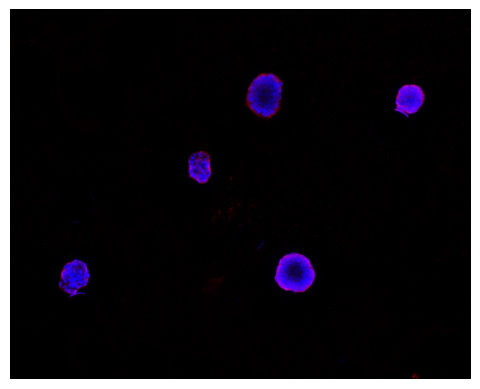

In [13]:
# Check data's integrity and visualize the first image
verIm = cv2.imread(image_paths[0])
if verIm is None:
    print("Error: Failed to load the first image.")  
else:
    test_img_rgb = cv2.cvtColor(verIm, cv2.COLOR_BGR2RGB)
    plt.imshow(test_img_rgb)
    plt.axis('off')
    plt.show()
 

In [14]:
# Optinal: Run this cell to check the correction of format andverify all images in the directory, If images are trustfully, this is optinal. 


bad_images = verify_images(image_import(directory_path))
if  bad_images:
    print(f"Corrupted images found: {len(bad_images)}") #How many unqualified images in the folder
    for i in bad_images:
        print(f" - {i}") #Print the path of unqualified images
else:
    print("All images are valid and loaded successfully.")

found 4 images.
All images are valid and loaded successfully.


In [15]:
def batch_preprocess(image_dict, parallel = 4): 
    """
    This function support large number of image processing
    
    Parameters:
                image_dict: the dictionary contains original image data(key:str, item:np.array)
                parallel: int, define specific number of worker threads that asynchronously executing callables

    Return: 
                processed_dict, A dictionary contain image addreesses(key: str) and np arrays([2,3])
                tags_dict, A dictionary contain image addresses(key: str) and metrics of parameter for preporcessing
    """
    
    processed_dict = {}
    tags_dict = {}
    with ThreadPoolExecutor(max_workers = parallel) as exe:
        futures = {exe.submit(preprocessing, img): path for path, img in image_dict.items()} #dispatches preprocessing function to be executed 
        for p in futures: 
            path = futures[p] #retrieve the key
            processed_img, tags = p.result() #retrieve the return of preprocessing, images and tags
            processed_dict[path] = processed_img
            tags_dict[path] = tags

    return processed_dict, tags_dict

Add support code here to visulize functions and the result of preprocessing

In [16]:
def show_image(img_array, title=None, figsize=(6,6)):
    plt.figure(figsize=figsize)
    plt.imshow(img_array)
    plt.title(title)
    plt.axis('off')
    plt.show()

def compare_image(original, preprocessed, title='Original', title2='Preprocessed'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(original)
    axes[0].set_title(title)
    axes[0].axis('off')
    
    axes[1].imshow(preprocessed)
    axes[1].set_title(title2)
    axes[1].axis('off')
    plt.show()



In [ ]:
def browse_compare_images(original_dict, preprocessed_dict, tag_dict=None):
    """
    
    """


    #verify the dictionaries used for comparison. Make sure the batches to be evaluated are the same.
    assert (set(original_dict.keys()) == set(preprocessed_dict.keys())), \
        "Original and preprocessed dictionaries must have the same keys"
    
    keys = list(original_dict.keys())
    N = len(keys)
    idx = 0

    # create a new UI modual
    out = widgets.Output()
    metrics_out = widgets.Output()
    
    p_btn = widgets.Button(description="Previous")
    n_btn = widgets.Button(description="Next")
    j_btn = widgets.Button(description="Go", layout=widgets.Layout(width='50px'))
    idx_label = widgets.Label(value=f"Image {idx+1} of {N}")
    jumpui = widgets.IntText(
        value=1, 
        min=1, 
        max=N,
        step=1, 
        description='Jump to:', 
        layout=widgets.Layout(width='180px')
    )

    # update function
    def update_display():
        # clear output
        out.clear_output(wait=True)
        metrics_out.clear_output(wait=True)
        
        path = keys[idx]
        original = original_dict[path]
        preprocessed = preprocessed_dict[path]
        
        # display selected image
        with out:
            fig, axes = plt.subplots(1, 2, figsize=(10, 6))
            
            axes[0].imshow(original)
            axes[0].set_title(f"Original: {path}", fontsize=10)
            axes[1].imshow(preprocessed)
            axes[1].set_title(f"Preprocessed: {path}", fontsize=10)
            
            axes[0].axis('off')
            axes[1].axis('off')
            
            plt.tight_layout()
            plt.show()
        
        # metrics setting
        with metrics_out:
            metrics = None
            if tag_dict is not None:
                tags = tag_dict.get(path, {})
                metrics = tags.get('eval_metrics', {})
                if not metrics: #if can't retrive the metrics from preprocessing step, do it in here
                    try:
                        metrics = evaluation_metrics(original, preprocessed)
                        if tag_dict is not None and path in tag_dict: #update the metrics result into the tags
                            tag_dict[path]['eval_metrics'] = metrics
                    except Exception as e:
                        print(f'error when calculating the metrics: {e}')
                # when the metrics in tags was read    
                if metrics:
                    print(f"contrast: {metrics['contrast_ratio']}x")
                    print(f"information entropy: {metrics['entropy_ratio']}x")
                    print(f"clearness: {metrics['sharpness_ratio']}x")
                    print(f"SNR: {metrics['noise_ratio']}x")
                    
                else:
                    print("No data avaliable for the evaluation")

        # update the new label and junping number
        idx_label.value = f"Image {idx+1} of {N}"
        jumpui.value = idx + 1

    # button setting
    def on_prev_clicked(b):
        nonlocal idx
        idx = (idx - 1) % N
        update_display()

    def on_next_clicked(b):
        nonlocal idx
        idx = (idx + 1) % N
        update_display()

    def on_jump_clicked(b):
        nonlocal idx
        if 1 <= jumpui.value <= N:
            idx = jumpui.value - 1
            update_display()
        else:
            jumpui.value = idx + 1

    def on_enter(change):
        nonlocal idx
        if 1 <= change['new'] <= N:
            idx = change['new'] - 1
            update_display()
        else:
            jumpui.value = idx + 1

    # 
    p_btn.on_click(on_prev_clicked)
    n_btn.on_click(on_next_clicked)
    j_btn.on_click(on_jump_clicked)
    jumpui.continuous_update = False
    jumpui.observe(on_enter, names='value')

    # UI setting
    buttons = widgets.HBox([p_btn, idx_label, n_btn], layout=widgets.Layout(justify_content='center'))
    jump_row = widgets.HBox([jumpui, j_btn], layout=widgets.Layout(justify_content='center'))
    ui = widgets.VBox([buttons, jump_row, out, metrics_out])
    display(ui)
    
    # display
    update_display()

In [26]:
 
original_images = load_images(image_paths)
processed_dict = {}
tags_dict = {}
for path, img in tqdm(original_images.items(), desc = "Preprocessing"):
    processed_img, tags = preprocessing(img, manual_tags={'need_background_correction': False})
    #processed_img, tags = preprocessing(img)
    processed_dict[path] = processed_img
    tags_dict[path] = tags

Successfully loaded 4 images.


Preprocessing: 100%|██████████| 4/4 [00:00<00:00, 24.93it/s]


In [27]:
browse_compare_images(original_images, processed_dict, tag_dict= tags_dict)

In [28]:
def save_preproiamge(processed_dict, output_dir, format = '.tif'):
    """
    Save the preprocessed image to the targeted directory
    
    Parameters:
                processed_dict: A dictionary contrain keys(image info, str) and items(2D arrays)
                output_dir: A string of the dictionary address
                format: the saved image format, tif format by default
    
    """

    os.makedirs(output_dir, exist_ok= True) # Note: this will create all non-existen directory on the pathway, no error will raise if the directory already exist
    for path, img in processed_dict.items():
        iuint8 = (img * 255.0).astype(np.uint8) #convert the normalized image back to uint8 format
        base = os.path.basename(path).split('.')[0]
        save_path = os.path.join(output_dir, f"{base}_preprocessed{format}")
        cv2.imwrite(save_path, iuint8)

In [29]:
def prepro_report(tags_dict, output_path = 'process report.csv'):
    """
    generate repot of processing tags and parameters for every image in the batch
    
    """
    rows = []
    for path, tags in tags_dict.items():
        row = {'image': os.path.basename(path), 'type': tags['image_type']} #id and type
        row.update({k: v for k, v in tags.items() if k != 'metrics' and k != 'image_type'}) # keep tag info in the row dictionary
        row.update(tags.get('metrics',{})) # now retrive score data for tagging evaluation
        rows.append(row)
    df =pd.DataFrame(rows) #each image info is stored in a row of dataframe
    df.to_csv(output_path, index = False) #as csv file 
    return df 




In [30]:
tags['eval_metrics']

{'contrast_original': np.float64(13.5772),
 'contrast_processed': np.float64(17.4752),
 'contrast_ratio': np.float64(1.287),
 'entropy_original': np.float64(5.716),
 'entropy_processed': np.float64(6.095),
 'entropy_ratio': np.float64(1.066),
 'sharpness_original': np.float64(17.56),
 'sharpness_processed': np.float64(68.45),
 'sharpness_ratio': np.float64(3.9),
 'noise_original': np.float64(99.5485),
 'noise_processed': np.float64(120.2674),
 'noise_ratio': np.float64(1.208)}